# 0. les biblios

In [60]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import sys
import subprocess
from mlxtend.frequent_patterns import apriori, association_rules
#pip install mlxtend

# 1. Charger environmental_fields_reports.csv

In [61]:
# Charger les données
df = pd.read_csv("environmental_field_reports.csv")

In [62]:
# 1. Dimensions et types de colonnes
print("Dimensions :", df.shape)
print("\nTypes de colonnes :")
df.info()

Dimensions : (30, 12)

Types de colonnes :
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   document_id               30 non-null     str  
 1   site_code                 30 non-null     str  
 2   document_date             30 non-null     str  
 3   document_type             30 non-null     str  
 4   author_name               29 non-null     str  
 5   author_organization       30 non-null     str  
 6   reporting_period          30 non-null     str  
 7   title                     30 non-null     str  
 8   text                      30 non-null     str  
 9   related_survey_id         30 non-null     str  
 10  related_device_reference  30 non-null     str  
 11  publication_status        30 non-null     str  
dtypes: str(12)
memory usage: 46.6 KB


In [63]:
# 2. Échantillon des données
print("\nPremières lignes :")
display(df.head())


Premières lignes :


,document_id,site_code,document_date,document_type,author_name,author_organization,reporting_period,title,text,related_survey_id,related_device_reference,publication_status
0,EFR-510088,KNT-KES,2024-04-02,ecological_incident_report,Anika Dren,Horizon Field Research Cooperative,2024-04,Post-Access Ecological Incident at KNT-KES,INCIDENT\r\nA post-access inspection was condu...,BAT-0000064,DEV-KNTKES-2,restricted
1,EFR-510082,KNT-JAK,2019-04-01,field_observation,Vera Waren,Pollinator Justice Network,2019-04,Field Observation 27,SITE AND TIME\r\nField observation at KNT-JAK ...,BAT-0001000,DEV-KNTJAK-3,restricted
2,EFR-510035,KNT-JQG,2022-09-08,field_observation,Uma Wessen,Horizon Field Research Cooperative,2022-09,Field Observation 28,SITE AND TIME\r\nField observation at KNT-JQG ...,BAT-0001037,DEV-KNTJQG-1,internal
3,EFR-510007,KNT-JQG,2025-02-15,field_observation,J. Varlan,Varlan Natural History Circle,2025-02,Field Observation 29,SITE AND TIME\r\nField observation at KNT-JQG ...,BAT-0001074,DEV-KNTJQG-1,public
4,EFR-510031,KNT-VLB,2020-07-22,field_observation,Jonah Bell,Bell Conservation Survey,2020-07,Field Observation 30,SITE AND TIME\r\nField observation at KNT-VLB ...,BAT-0001111,DEV-KNTVLB-2,internal


In [64]:
# 3. Doublons
print("Nombre de lignes dupliquées (strictement identiques) :", df.duplicated().sum())
print("Nombre de document_id dupliqués :", df['document_id'].duplicated().sum())

# Afficher les doublons de document_id s'il y en a
dupes = df[df['document_id'].duplicated(keep=False)]
if not dupes.empty:
    display(dupes.sort_values('document_id'))

Nombre de lignes dupliquées (strictement identiques) : 0
Nombre de document_id dupliqués : 0


# 2. Valeurs manquantes

In [65]:
# 4. Valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

print("\nPourcentage de manquants par colonne :")
print((df.isna().sum() / len(df) * 100).round(2))

Valeurs manquantes par colonne :
document_id                 0
site_code                   0
document_date               0
document_type               0
author_name                 1
author_organization         0
reporting_period            0
title                       0
text                        0
related_survey_id           0
related_device_reference    0
publication_status          0
dtype: int64

Pourcentage de manquants par colonne :
document_id                 0.00
site_code                   0.00
document_date               0.00
document_type               0.00
author_name                 3.33
author_organization         0.00
reporting_period            0.00
title                       0.00
text                        0.00
related_survey_id           0.00
related_device_reference    0.00
publication_status          0.00
dtype: float64


In [66]:
# Voir les lignes où author_name est manquant
missing_name = df[df['author_name'].isna()]
display(missing_name)

,document_id,site_code,document_date,document_type,author_name,author_organization,reporting_period,title,text,related_survey_id,related_device_reference,publication_status
23,EFR-510012,KNT-VXR,2021-06-20,sensor_quality_report,NaN,Threshold Earth Observatory,2021-06,Sensor Quality Review 49,DEVICE\r\nQuality review for DEV-KNTVXR-2 at K...,BAT-0001814,DEV-KNTVXR-2,internal


In [67]:
df['author_name'] = df['author_name'].fillna('Unknown')

In [68]:
print(df.isna().sum())

document_id                 0
site_code                   0
document_date               0
document_type               0
author_name                 0
author_organization         0
reporting_period            0
title                       0
text                        0
related_survey_id           0
related_device_reference    0
publication_status          0
dtype: int64


# 3. Doublons

### a- Doublons de lignes

In [69]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values('document_id'))

Nombre de lignes dupliquées : 0


,document_id,site_code,document_date,document_type,author_name,author_organization,reporting_period,title,text,related_survey_id,related_device_reference,publication_status


### b- Doublons de colonnes 

In [70]:
# 1. Vérifier si des noms de colonnes sont strictement identiques
noms_doublons = df.columns[df.columns.duplicated()]
print("Noms de colonnes en double :", noms_doublons.tolist())

# 2. Vérifier si le contenu de certaines colonnes est 100% identique
contenu_doublons = df.columns[df.T.duplicated()]
print("Colonnes avec un contenu dupliqué :", contenu_doublons.tolist())

Noms de colonnes en double : []
Colonnes avec un contenu dupliqué : []


# 4. Formats incohérents

### Les types de chaque colonnes :

In [71]:
print(df.dtypes)

document_id                 str
site_code                   str
document_date               str
document_type               str
author_name                 str
author_organization         str
reporting_period            str
title                       str
text                        str
related_survey_id           str
related_device_reference    str
publication_status          str
dtype: object


### - Vérifier le format de document_id

In [72]:
# Pattern pour s'assurer que ça commence par EFR- suivi de 5 chiffres (ou plus)
pattern_doc = r'^EFR-\d+$'

non_conformes = df[~df['document_id'].astype(str).str.match(pattern_doc, na=False)]
print("Document ID non conformes :", len(non_conformes))

Document ID non conformes : 0


### - Vérifier le format de site_code (catégorielle)

In [73]:
pattern_site = r'^[A-Z]{3}-[A-Z]{3}$'
non_conformes = df[~df['site_code'].astype(str).str.match(pattern_site)]
print("Site code non conformes :", len(non_conformes))
# Afficher les valeurs uniques et leur fréquence pour site_code
print(df['site_code'].value_counts(dropna=False))

Site code non conformes : 0
site_code
KNT-DMJ    3
KNT-JQG    2
KNT-VLB    2
KNT-CHP    2
KNT-YRG    2
KNT-WUQ    2
KNT-GGN    2
KNT-QWU    2
KNT-TLQ    2
KNT-UJJ    2
KNT-VXR    2
KNT-TEX    2
KNT-BME    2
KNT-KES    1
KNT-JAK    1
KNT-XAC    1
Name: count, dtype: int64


### - Vérifier le format de document_date

In [74]:
# Pattern pour le format standard YYYY-MM-DD (ex: 2024-04-02)
pattern_date = r'^\d{4}-\d{2}-\d{2}$'

# 1. Vérifier via le pattern regex
non_conformes_regex = df[~df['document_date'].astype(str).str.match(pattern_date, na=False)]
print("Dates ne respectant pas le format YYYY-MM-DD :", len(non_conformes_regex))

# 2. Vérification robuste avec pandas (pour voir s'il y a des valeurs corrompues ou NaT)
dates_converties = pd.to_datetime(df['document_date'], errors='coerce')
print("Valeurs non convertibles en datetime (NaT) :", dates_converties.isnull().sum())

Dates ne respectant pas le format YYYY-MM-DD : 0
Valeurs non convertibles en datetime (NaT) : 0


### - Vérifier le format de document_type (catégorielle)

In [75]:
# Afficher les types de documents et leur fréquence
print(df['document_type'].value_counts(dropna=False))

document_type
ecological_incident_report    6
field_observation             6
monitoring_report             6
cave_access_note              6
sensor_quality_report         6
Name: count, dtype: int64


### - Vérifier le format d'author_name

In [76]:
# Pattern pour vérifier un format de nom standard (ex: Prénom Nom ou P. Nom)
pattern_author = r'^[A-Z][a-z]+(\.|\s)[A-Z][a-z]+$'

non_conformes_author = df[~df['author_name'].astype(str).str.match(pattern_author, na=False)]
print("Noms non conformes au format standard :", len(non_conformes_author))
print(non_conformes_author['author_name'])

Noms non conformes au format standard : 2
3     J. Varlan
23      Unknown
Name: author_name, dtype: str


### - Vérifier le format de author_organization (catégorielle)

In [77]:
# 1. Vérifier les valeurs manquantes et la répartition
print(df['author_organization'].value_counts(dropna=False))

author_organization
Horizon Field Research Cooperative        6
Avelora Agricultural Resilience Agency    5
Threshold Earth Observatory               5
Pollinator Justice Network                4
Belen Agro-Industries                     4
Asterion Clinical Institute               2
Varlan Natural History Circle             1
Bell Conservation Survey                  1
Marot Ecological Policy Office            1
Lantern Investigative Bureau              1
Name: count, dtype: int64


### - Vérifier le format de reporting_period

In [78]:
# 1. Pattern pour un format de type année-mois (ex: 2024-04)
pattern_period = r'^\d{4}-\d{2}$'

non_conformes_period = df[~df['reporting_period'].astype(str).str.match(pattern_period, na=False)]
print("Périodes non conformes au format YYYY-MM :", len(non_conformes_period))

Périodes non conformes au format YYYY-MM : 0


### - Vérifier le format de title

In [79]:
print(df['title'].value_counts(dropna=False))

title
Post-Access Ecological Incident at KNT-KES    1
Field Observation 27                          1
Field Observation 28                          1
Field Observation 29                          1
Field Observation 30                          1
Field Observation 31                          1
Field Observation 32                          1
Monthly Monitoring Report 33                  1
Monthly Monitoring Report 34                  1
Monthly Monitoring Report 35                  1
Monthly Monitoring Report 36                  1
Monthly Monitoring Report 37                  1
Monthly Monitoring Report 38                  1
Cave Access Note 39                           1
Cave Access Note 40                           1
Cave Access Note 41                           1
Cave Access Note 42                           1
Cave Access Note 43                           1
Cave Access Note 44                           1
Sensor Quality Review 45                      1
Sensor Quality Review 46          

### - Vérifier le format de text

In [80]:
print(df['text'].value_counts(dropna=False))

text
INCIDENT\r\nA post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.\r\n\r\nEVIDENCE\r\nDevice uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.\r\n\r\nIMMEDIATE ACTION\r\nThe entrance was photographed, the cut material was retained, and the station configuration was checked against the prior record. A repeat survey and 

### - Vérifier le format de related_survey_id (catégorielle)

In [81]:
pattern_survey = r'^BAT-\d{7}$'
non_conformes_survey = df[~df['related_survey_id'].astype(str).str.match(pattern_survey, na=False)]
print("related_survey_id non conformes :", len(non_conformes_survey))
print(df['related_survey_id'].value_counts(dropna=False).head())

related_survey_id non conformes : 0
related_survey_id
BAT-0000064    1
BAT-0001000    1
BAT-0001037    1
BAT-0001074    1
BAT-0001111    1
Name: count, dtype: int64


### - Vérifier le format de related_device_reference (catégorielle)

In [82]:
pattern_device = r'^DEV-[A-Z0-9]+-\d+$'
non_conformes_device = df[~df['related_device_reference'].astype(str).str.match(pattern_device, na=False)]
print("\nrelated_device_reference non conformes :", len(non_conformes_device))
print(df['related_device_reference'].value_counts(dropna=False).head())


related_device_reference non conformes : 0
related_device_reference
DEV-KNTDMJ-3    3
DEV-KNTJQG-1    2
DEV-KNTVLB-2    2
DEV-KNTCHP-3    2
DEV-KNTYRG-1    2
Name: count, dtype: int64


### - Vérifier le format de publication_status (catégorielle)

In [83]:
print(df['publication_status'].value_counts(dropna=False))

publication_status
restricted    12
public        10
internal       8
Name: count, dtype: int64


### Vérification explicite des caractères sentinelles parasites ('?', '-', 'NA', etc.)

In [84]:
valeurs_suspectes = ['?', ' ?', '?-', '-', 'UNKNOWN', 'unknown', 'N/A', 'null', 'None']
suspects_trouves = {}

for col in df.columns:
    nb = df[col].astype(str).str.strip().isin(valeurs_suspectes).sum()
    if nb > 0:
        suspects_trouves[col] = nb

print("Caractères sentinelles / '?' détectés par colonne :", suspects_trouves if suspects_trouves else "Aucun '?' ou valeur sentinelle détectée !")


Caractères sentinelles / '?' détectés par colonne : Aucun '?' ou valeur sentinelle détectée !


# 5. Télécharger le csv nettoyé

In [85]:
df.to_csv('cleaned/environmental_field_reports_cleaned.csv', index=False)

# 6. Pas colonnes numériques donc pas de outliers

Il y a 0 colonne numérique continue (pas de mesures physiques, pas de températures, pas de comptages continus).
Tout est textuel, catégoriel, ou temporel.
Donc mathématiquement, on ne peut pas faire de boxplot classique d'outliers numériques ni de matrice de corrélation de Pearson classique.

# 7. Histogrammes et statistiques

### Statistiques descriptives

In [88]:
# 1. Statistiques descriptives
print("Statistiques descriptives globales (colonnes catégorielles / textuelles)")
display(df.describe(include='all'))

print("\nFréquences des variables clés")
for col in ['document_type', 'publication_status', 'site_code', 'author_organization']:
    print(f"\nRépartition de {col} :")
    print(df[col].value_counts())


Statistiques descriptives globales (colonnes catégorielles / textuelles)


,document_id,site_code,document_date,document_type,author_name,author_organization,reporting_period,title,text,related_survey_id,related_device_reference,publication_status
count,30,30,30,30,30,30,30,30,30,30,30,30
unique,30,16,30,5,29,10,25,30,30,30,16,3
top,EFR-510088,KNT-DMJ,2024-04-02,ecological_incident_report,Anika Dren,Horizon Field Research Cooperative,2019-04,Post-Access Ecological Incident at KNT-KES,INCIDENT\r\nA post-access inspection was condu...,BAT-0000064,DEV-KNTDMJ-3,restricted
freq,1,3,1,6,2,6,2,1,1,1,3,12



Fréquences des variables clés

Répartition de document_type :
document_type
ecological_incident_report    6
field_observation             6
monitoring_report             6
cave_access_note              6
sensor_quality_report         6
Name: count, dtype: int64

Répartition de publication_status :
publication_status
restricted    12
public        10
internal       8
Name: count, dtype: int64

Répartition de site_code :
site_code
KNT-DMJ    3
KNT-JQG    2
KNT-VLB    2
KNT-CHP    2
KNT-YRG    2
KNT-WUQ    2
KNT-GGN    2
KNT-QWU    2
KNT-TLQ    2
KNT-UJJ    2
KNT-VXR    2
KNT-TEX    2
KNT-BME    2
KNT-KES    1
KNT-JAK    1
KNT-XAC    1
Name: count, dtype: int64

Répartition de author_organization :
author_organization
Horizon Field Research Cooperative        6
Avelora Agricultural Resilience Agency    5
Threshold Earth Observatory               5
Pollinator Justice Network                4
Belen Agro-Industries                     4
Asterion Clinical Institute               2
Varlan Nat

### Visualiser les distributions (Seaborn : barplots, boxplot & histogramme)

C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\1444376124.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_analysis, y='document_type', ax=axes[0], palette='Blues_r', order=df_analysis['document_type'].value_counts().index)
C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\1444376124.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_analysis, x='publication_status', ax=axes[1], palette='Set2')


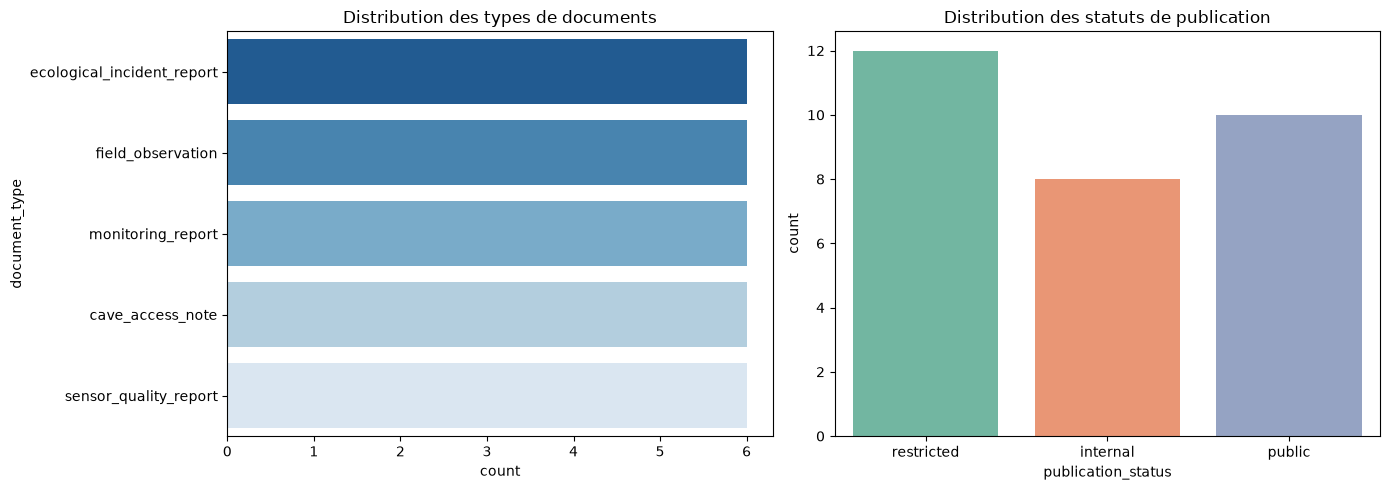

In [90]:
# 2. Distributions des variables clés
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution des types de documents
sns.countplot(data=df_analysis, y='document_type', ax=axes[0], palette='Blues_r', order=df_analysis['document_type'].value_counts().index)
axes[0].set_title("Distribution des types de documents")

# Distribution du statut de publication
sns.countplot(data=df_analysis, x='publication_status', ax=axes[1], palette='Set2')
axes[1].set_title("Distribution des statuts de publication")

plt.tight_layout()
plt.show()

c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


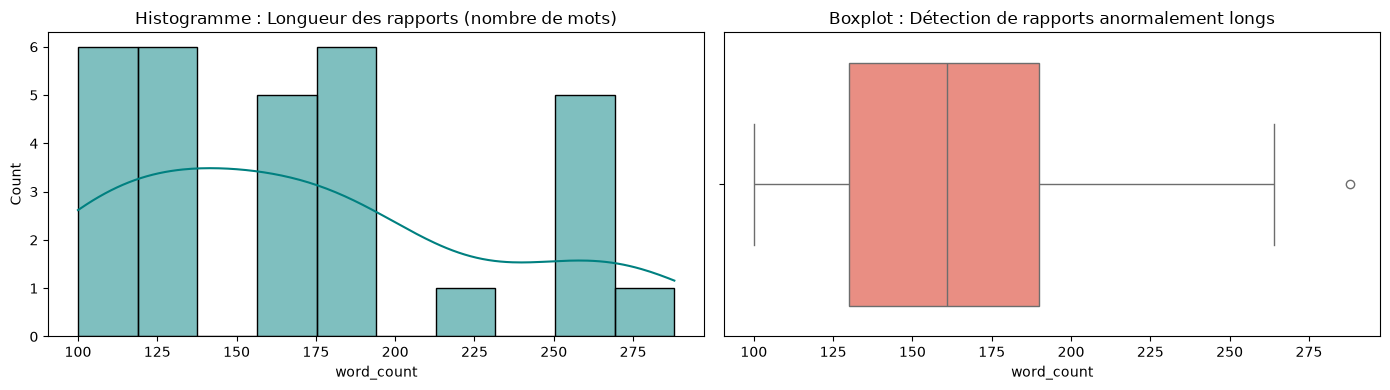

In [91]:
# 2.bis Longueur des textes (histogramme + boxplot)
df_analysis['word_count'] = df_analysis['text'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_analysis['word_count'], bins=10, kde=True, ax=axes[0], color='teal')
axes[0].set_title("Histogramme : Longueur des rapports (nombre de mots)")

sns.boxplot(x=df_analysis['word_count'], ax=axes[1], color='salmon')
axes[1].set_title("Boxplot : Détection de rapports anormalement longs")

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\1263377612.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y='document_type', x='word_count', palette='Blues_d')
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.

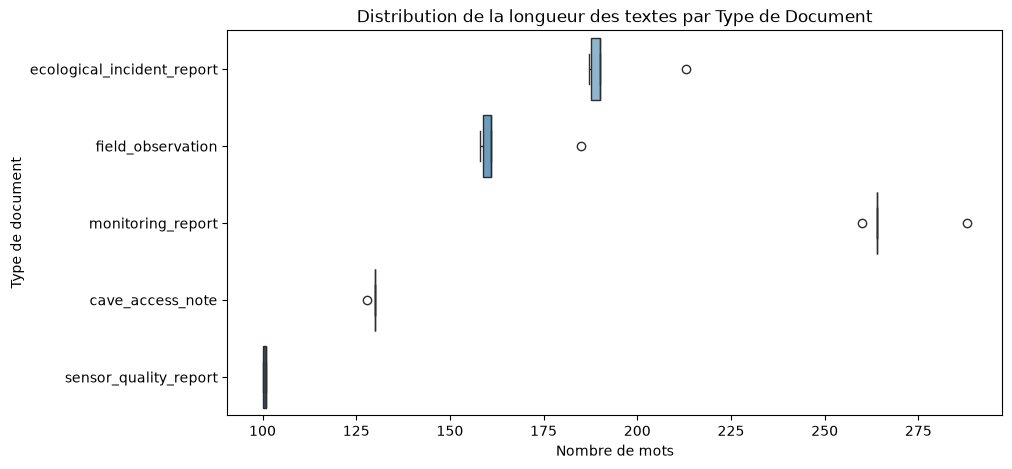

In [35]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, y='document_type', x='word_count', palette='Blues_d')
plt.title("Distribution de la longueur des textes par Type de Document")
plt.xlabel("Nombre de mots")
plt.ylabel("Type de document")
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\2593861800.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


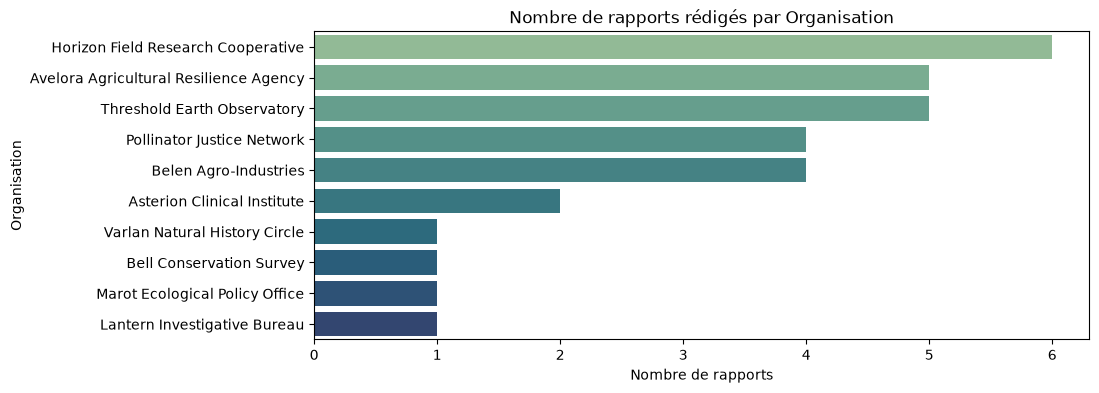

In [36]:
plt.figure(figsize=(10, 4))
sns.countplot(
    data=df, 
    y='author_organization', 
    order=df['author_organization'].value_counts().index, 
    palette='crest'
)
plt.title("Nombre de rapports rédigés par Organisation")
plt.xlabel("Nombre de rapports")
plt.ylabel("Organisation")
plt.show()


### Isoler et lire l'outlier révélé par le boxplot

In [93]:
# Identifier le rapport atypique (l'outlier du boxplot)
outlier_doc = df_analysis[df_analysis['word_count'] > 275]
print("--- RAPPORT IDENTIFIÉ COMME OUTLIER DE LONGUEUR ---")
display(outlier_doc[['document_id', 'site_code', 'document_date', 'document_type', 'title', 'word_count']])

print("\nExtrait du texte de cet outlier :")
print(outlier_doc['text'].iloc[0][:400] + "...")


--- RAPPORT IDENTIFIÉ COMME OUTLIER DE LONGUEUR ---


,document_id,site_code,document_date,document_type,title,word_count
7,EFR-510026,KNT-CHP,2021-10-16,monitoring_report,Monthly Monitoring Report 33,288



Extrait du texte de cet outlier :
PERIOD
Monitoring report for KNT-CHP, focused on orchard pollination survey.

METHODS
Acoustic, visual, environmental, orchard, and device records were compared. Survey BAT-0001222 was included with effort and weather controls.

RESULTS
Activity followed the broad seasonal pattern, with local variation around rainfall and flowering. Device coverage was adequate for trend interpretation.

...


Conclusion sur le traitement de l'outlier textuel :

Constat : Le boxplot isole un rapport (EFR-510026 à 288 mots).

Diagnostic : Cet outlier n'est pas un artefact ou une donnée corrompue, mais un rapport plus détaillé intégrant une clause de permis de recherche (PERMIT CONTEXT).

Décision : Conservation intégrale de la ligne dans le jeu de données, aucune suppression ni tronquage.

# 8. Feature Engineering : Tendances temporelles sur les dates (par mois / année)

In [94]:
df_analysis = pd.read_csv('cleaned/environmental_field_reports_cleaned.csv')
df_analysis['word_count'] = df_analysis['text'].apply(lambda x: len(str(x).split()))

C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\1593896520.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_analysis, x='year', ax=axes[0], palette='Blues_d')
C:\Users\DELL\AppData\Local\Temp\ipykernel_12696\1593896520.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_analysis, x='month', ax=axes[1], palette='Purples_d')


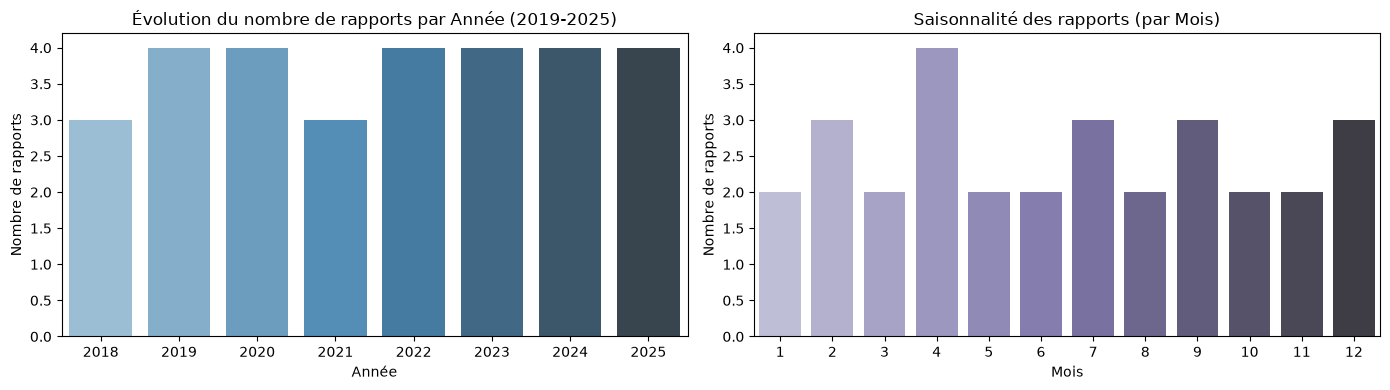

In [95]:
# 5. Tendances temporelles (Évolution par Année et Mois)
df_analysis['document_date'] = pd.to_datetime(df_analysis['document_date'])
df_analysis['year'] = df_analysis['document_date'].dt.year
df_analysis['month'] = df_analysis['document_date'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# A. Évolution du nombre de rapports par an
sns.countplot(data=df_analysis, x='year', ax=axes[0], palette='Blues_d')
axes[0].set_title("Évolution du nombre de rapports par Année (2019-2025)")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Nombre de rapports")

# B. Saisonnalité (par mois)
sns.countplot(data=df_analysis, x='month', ax=axes[1], palette='Purples_d')
axes[1].set_title("Saisonnalité des rapports (par Mois)")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Nombre de rapports")

plt.tight_layout()
plt.show()

### Détection des irrégularités suspectes (pics, creux, valeurs rares)

In [97]:
# A. Détection du creux de données (Sites avec un seul rapport)
counts_sites = df_analysis['site_code'].value_counts()
print("IRRÉGULARITÉ 1 : SITES À COUVERTURE ANORMALEMENT FAIBLE (1 seul rapport)")
display(counts_sites[counts_sites == 1])

IRRÉGULARITÉ 1 : SITES À COUVERTURE ANORMALEMENT FAIBLE (1 seul rapport)


site_code
KNT-KES    1
KNT-JAK    1
KNT-XAC    1
Name: count, dtype: int64

In [ ]:
# B. Recherche d'alertes textuelles spécifiques (mots-clés d'infraction / incident)
mots_cles = ['cut', 'incident', 'unauthorized', 'handling', 'deficit', 'breach']
pattern = '|'.join(mots_cles)

df_analysis['alerte_detectee'] = df_analysis['text'].str.contains(pattern, case=False, regex=True)
rapports_critiques = df_analysis[df_analysis['alerte_detectee']]

print(f"\n IRRÉGULARITÉ 2 : RAPPORTS SIGNALANT DES INCIDENTS MATÉRIELS / EFFRACTIONS ({len(rapports_critiques)})")
display(rapports_critiques[['document_id', 'site_code', 'document_date', 'document_type', 'publication_status', 'related_survey_id', 'title']])

# 9. Gestion des valeurs categorielles (colonnes catégorielles)

### a. Encodage ordinal (pour publication_status)

In [98]:
mapping_publication = {'internal': 0, 'restricted': 1, 'public': 2}
df_analysis['publication_status_encoded'] = df_analysis['publication_status'].map(mapping_publication)

print(df_analysis[['publication_status', 'publication_status_encoded']].drop_duplicates())

  publication_status  publication_status_encoded
0         restricted                           1
2           internal                           0
3             public                           2


### b. Encodage One-Hot (pour les variables nominales)

In [99]:
colonnes_nominales = ['document_type', 'site_code', 'author_organization']

# One-hot encoding
df_encoded = pd.get_dummies(df_analysis, columns=colonnes_nominales, dtype=int)
print("Dimensions de df_encoded :", df_encoded.shape)


Dimensions de df_encoded : (30, 44)


### - Affichage : 

In [100]:
# Affichage des dimensions et des premières lignes après encodage
print("Dimensions du DataFrame :", df_encoded.shape)
df_encoded.head(2)

Dimensions du DataFrame : (30, 44)


,document_id,document_date,author_name,reporting_period,title,text,related_survey_id,related_device_reference,publication_status,word_count,...,author_organization_Asterion Clinical Institute,author_organization_Avelora Agricultural Resilience Agency,author_organization_Belen Agro-Industries,author_organization_Bell Conservation Survey,author_organization_Horizon Field Research Cooperative,author_organization_Lantern Investigative Bureau,author_organization_Marot Ecological Policy Office,author_organization_Pollinator Justice Network,author_organization_Threshold Earth Observatory,author_organization_Varlan Natural History Circle
0,EFR-510088,2024-04-02,Anika Dren,2024-04,Post-Access Ecological Incident at KNT-KES,INCIDENT\r\nA post-access inspection was condu...,BAT-0000064,DEV-KNTKES-2,restricted,213,...,0,0,0,0,1,0,0,0,0,0
1,EFR-510082,2019-04-01,Vera Waren,2019-04,Field Observation 27,SITE AND TIME\r\nField observation at KNT-JAK ...,BAT-0001000,DEV-KNTJAK-3,restricted,185,...,0,0,0,0,0,0,0,1,0,0


# 10. Corrélations

### Corrélations numériques avec df.corr() et Heatmap

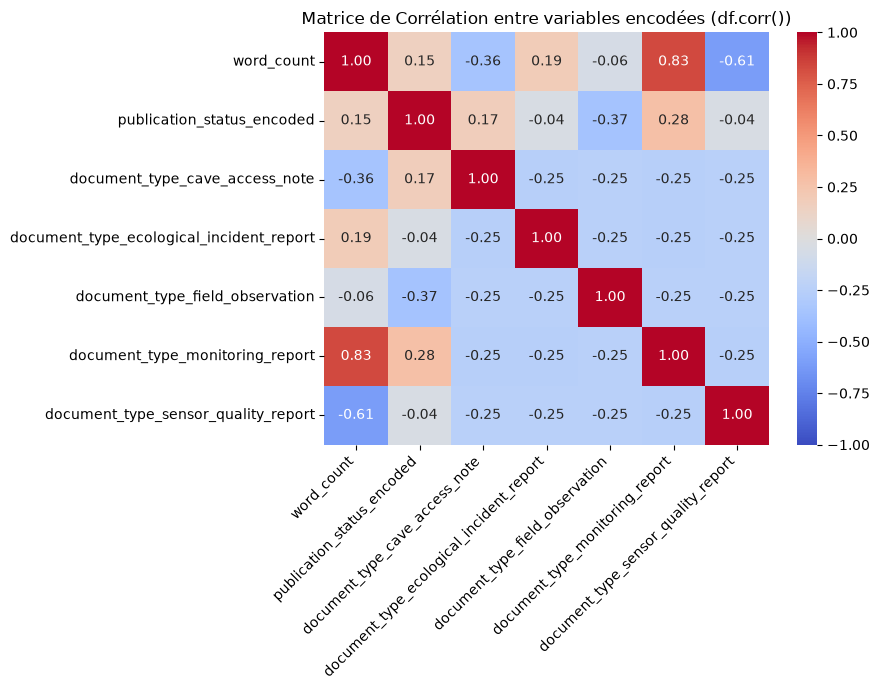

In [101]:
# 1. On injecte word_count directement dans df_encoded
df_encoded['word_count'] = df_analysis['text'].apply(lambda x: len(str(x).split()))

# Sélection des colonnes numériques encodées pertinentes
cols_corr = [
    'word_count', 
    'publication_status_encoded',
    'document_type_cave_access_note',
    'document_type_ecological_incident_report',
    'document_type_field_observation',
    'document_type_monitoring_report',
    'document_type_sensor_quality_report'
]

# Calcul de la matrice de corrélation
matrice_corr = df_encoded[cols_corr].corr()

# Affichage de la heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(matrice_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title("Matrice de Corrélation entre variables encodées (df.corr())")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Tableaux croisés (pd.crosstab)

--- TABLE CROISÉE : Type de Document vs Statut de publication ---


publication_status,internal,public,restricted,All
document_type,,,,
cave_access_note,1,3,2,6
ecological_incident_report,1,1,4,6
field_observation,4,1,1,6
monitoring_report,1,4,1,6
sensor_quality_report,1,1,4,6
All,8,10,12,30


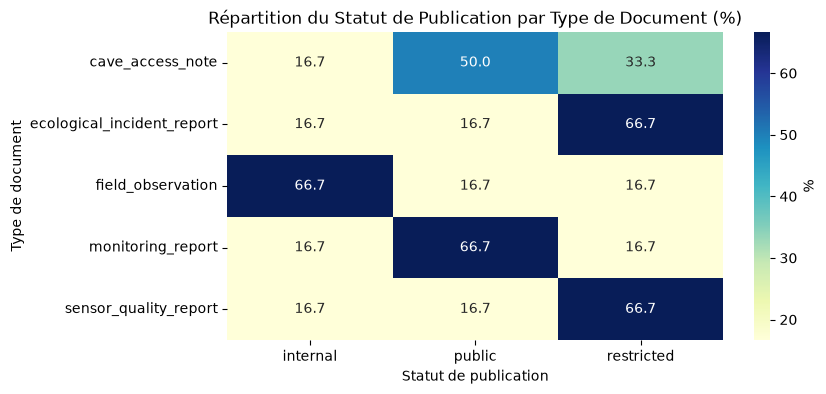

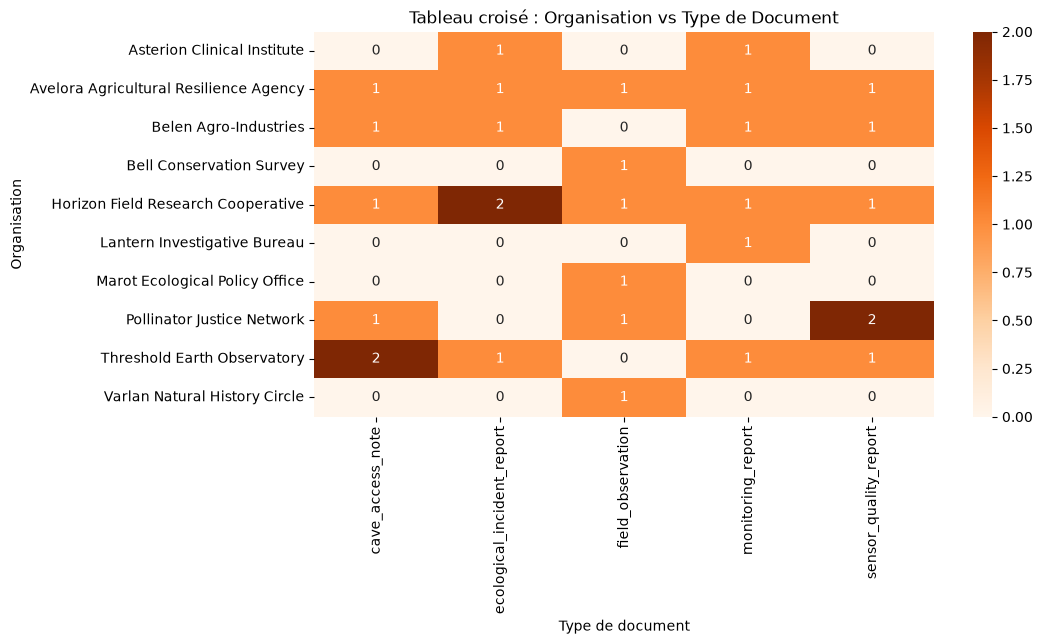

In [102]:
# A. Type de document vs Statut de publication
ct_status = pd.crosstab(df_analysis['document_type'], df_analysis['publication_status'], margins=True)
print("--- TABLE CROISÉE : Type de Document vs Statut de publication ---")
display(ct_status)

# Visualisation en heatmap (%)
plt.figure(figsize=(8, 4))
sns.heatmap(pd.crosstab(df_analysis['document_type'], df_analysis['publication_status'], normalize='index') * 100, 
            annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '%'})
plt.title("Répartition du Statut de Publication par Type de Document (%)")
plt.xlabel("Statut de publication")
plt.ylabel("Type de document")
plt.show()

# B. Organisation vs Type de Document
ct_org = pd.crosstab(df_analysis['author_organization'], df_analysis['document_type'])
plt.figure(figsize=(10, 5))
sns.heatmap(ct_org, annot=True, fmt='d', cmap='Oranges')
plt.title("Tableau croisé : Organisation vs Type de Document")
plt.xlabel("Type de document")
plt.ylabel("Organisation")
plt.show()

### Ce que ça révèle pour l'enquête : 

Dès qu'il y a un incident écologique ou une panne de capteur, l'information est classée confidentielle (restricted).

# 11. Ordonner et regrouper (BLOCS 2 : Clustering de Textes)

### ÉTAPE 1: Vectorisation TF-IDF

In [103]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Vectorisation TF-IDF (max 30 features pour lisibilité)
vectorizer = TfidfVectorizer(max_features=30, min_df=2, max_df=0.8, stop_words='english')
X_tfidf = vectorizer.fit_transform(df_analysis['text'])

# Convertir en dense
X_dense = X_tfidf.toarray()

print(f"Matrice TF-IDF : {X_tfidf.shape}")
print(f"Vocabulaire : {vectorizer.get_feature_names_out()[:15]}")

Matrice TF-IDF : (30, 30)
Vocabulaire : ['acoustic' 'changes' 'claim' 'convert' 'count' 'cycle' 'dev' 'exposure'
 'lower' 'maintenance' 'movement' 'neighboring' 'observed' 'orchard'
 'ordinary']


### ÉTAPE 2: Standardisation

In [104]:
# Standardiser (moyenne=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_dense)

print(f"Moyenne : {X_scaled.mean():.6f}")
print(f"Écart-type : {X_scaled.std():.6f}")

Moyenne : 0.000000
Écart-type : 1.000000


### ÉTAPE 3: Déterminer le nombre de clusters (Coude + Silhouette)

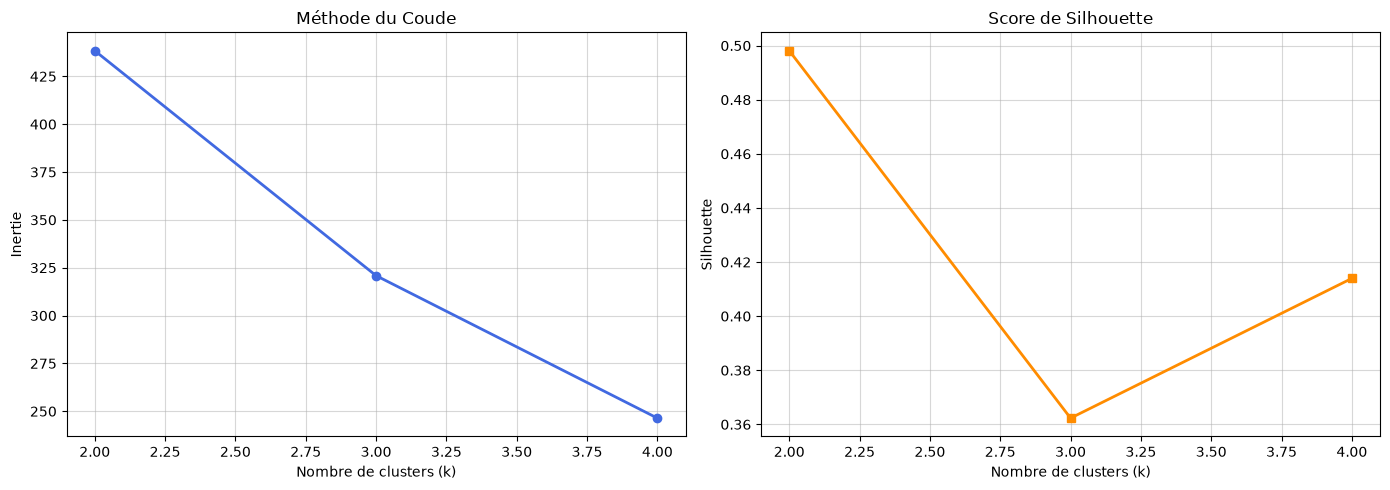

Scores de Silhouette :
k = 2 : 0.4981
k = 3 : 0.3623
k = 4 : 0.4140


In [105]:
# Recherche du k optimal
k_range = range(2, 5)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, km.labels_))

# Visualiser
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, marker='o', color='royalblue', lw=2)
axes[0].set_title("Méthode du Coude")
axes[0].set_xlabel("Nombre de clusters (k)")
axes[0].set_ylabel("Inertie")
axes[0].grid(True, alpha=0.5)

axes[1].plot(k_range, silhouette_scores, marker='s', color='darkorange', lw=2)
axes[1].set_title("Score de Silhouette")
axes[1].set_xlabel("Nombre de clusters (k)")
axes[1].set_ylabel("Silhouette")
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# Afficher les scores
print("Scores de Silhouette :")
for k, s in zip(k_range, silhouette_scores):
    print(f"k = {k} : {s:.4f}")

### ÉTAPE 4: Appliquer K-Means (k=2)

In [106]:
# K-Means optimal
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df_analysis['cluster_text'] = kmeans.fit_predict(X_scaled)

print(f"Distribution des clusters :")
print(df_analysis['cluster_text'].value_counts().sort_index())

Distribution des clusters :
cluster_text
0    23
1     7
Name: count, dtype: int64


### ÉTAPE 5: PCA 2D + Dendrogramme

Variance expliquée : PC1=58.9% + PC2=14.0%


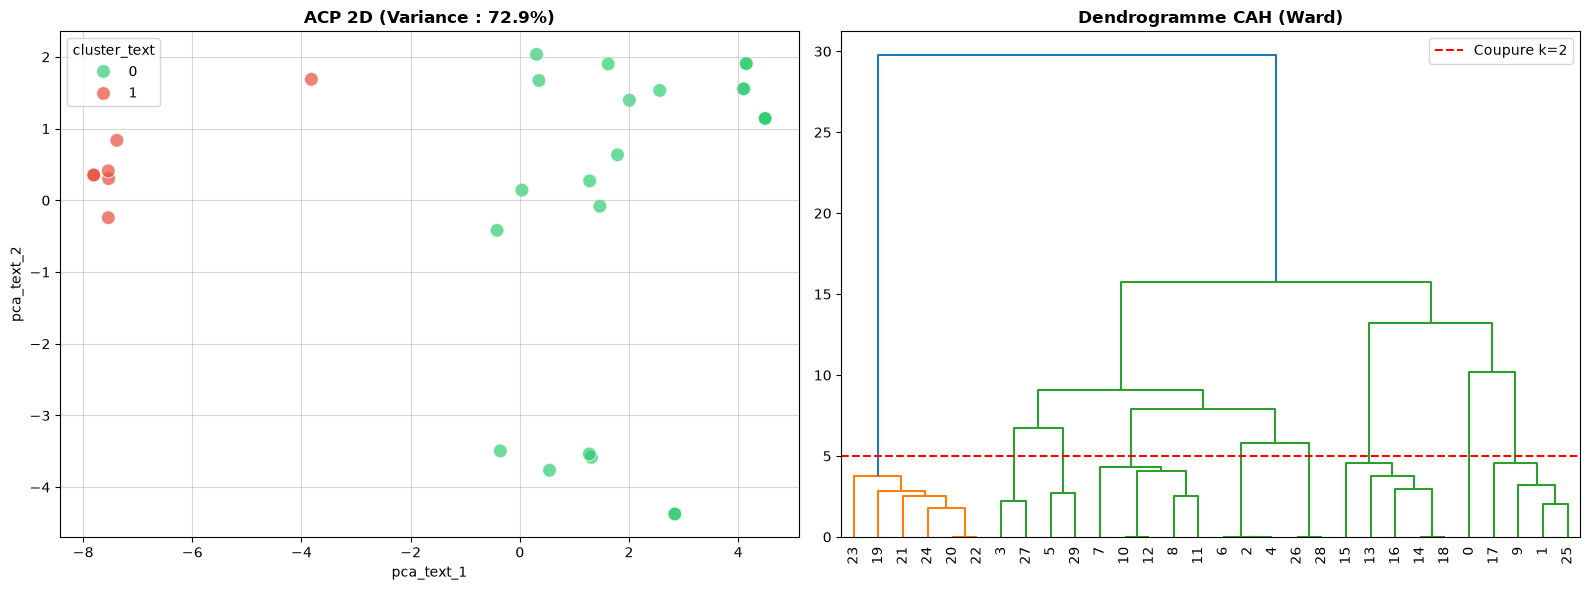

In [107]:
# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_analysis['pca_text_1'] = X_pca[:, 0]
df_analysis['pca_text_2'] = X_pca[:, 1]
var_exp = pca.explained_variance_ratio_ * 100

print(f"Variance expliquée : PC1={var_exp[0]:.1f}% + PC2={var_exp[1]:.1f}%")

# Visualisation ACP + Dendrogramme
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ACP 2D
colors = ['#2ecc71', '#e74c3c']
sns.scatterplot(data=df_analysis, x='pca_text_1', y='pca_text_2', hue='cluster_text', 
                palette=colors, alpha=0.7, s=100, ax=axes[0])
axes[0].set_title(f"ACP 2D (Variance : {var_exp.sum():.1f}%)", fontweight='bold')
axes[0].grid(True, alpha=0.5)

# Dendrogramme
linkage_mat = linkage(X_scaled, method='ward')
dendrogram(linkage_mat, ax=axes[1], leaf_rotation=90)
axes[1].set_title("Dendrogramme CAH (Ward)", fontweight='bold')
axes[1].axhline(y=5, color='r', linestyle='--', label='Coupure k=2')
axes[1].legend()

plt.tight_layout()
plt.show()

# 12. Détection d'anomalies (BLOCS 3 : Anomalies Textuelles)

### ÉTAPE 1 : Détection Univariée (Z-Score par feature TF-IDF)

In [108]:
# Z-Score univarié sur chaque feature TF-IDF
from scipy.stats import zscore

univariate_anomalies = []
for i in range(X_scaled.shape[1]):
    z_scores = np.abs(zscore(X_scaled[:, i]))
    anomaly_mask = z_scores > 3  # Seuil 3-sigma
    if anomaly_mask.sum() > 0:
        univariate_anomalies.append({
            'feature': vectorizer.get_feature_names_out()[i],
            'doc_indices': np.where(anomaly_mask)[0].tolist(),
            'z_scores': z_scores[anomaly_mask].tolist()
        })

df_analysis['univariate_anomaly'] = 0
for anom in univariate_anomalies:
    for idx in anom['doc_indices']:
        df_analysis.loc[idx, 'univariate_anomaly'] = 1

print(f"Univariée: {df_analysis['univariate_anomaly'].sum()} anomalies détectées")

Univariée: 2 anomalies détectées


### ÉTAPE 2 : Isolation Forest + LOF + visualisation PCA 2D et Anomalies

In [109]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Isolation Forest
iso_forest = IsolationForest(contamination=0.2, random_state=42)
df_analysis['anomaly_if'] = iso_forest.fit_predict(X_scaled)

# LOF
lof = LocalOutlierFactor(n_neighbors=5)
df_analysis['anomaly_lof'] = lof.fit_predict(X_scaled)

# Synthèse : documents flaggés par au moins une méthode
df_analysis['is_anomaly'] = ((df_analysis['anomaly_if'] == -1) | (df_analysis['anomaly_lof'] == -1)).astype(int)
print(f"Anomalies détectées : {df_analysis['is_anomaly'].sum()} / {len(df_analysis)}")

# Afficher les documents considérés comme anomalies
print(df_analysis[df_analysis['is_anomaly'] == 1])

Anomalies détectées : 6 / 30
   document_id site_code document_date               document_type  \
0   EFR-510088   KNT-KES    2024-04-02  ecological_incident_report   
17  EFR-510122   KNT-QWU    2019-12-05            cave_access_note   
19  EFR-510097   KNT-TLQ    2025-10-19       sensor_quality_report   
21  EFR-510003   KNT-UJJ    2023-08-06       sensor_quality_report   
23  EFR-510012   KNT-VXR    2021-06-20       sensor_quality_report   
24  EFR-510060   KNT-VXR    2024-11-27       sensor_quality_report   

    author_name                     author_organization reporting_period  \
0    Anika Dren      Horizon Field Research Cooperative          2024-04   
17   Jora Boras  Avelora Agricultural Resilience Agency          2019-12   
19  Farah Norel              Pollinator Justice Network          2025-10   
21  Orin Kassen                   Belen Agro-Industries          2023-08   
23      Unknown             Threshold Earth Observatory          2021-06   
24   Amina Elen         

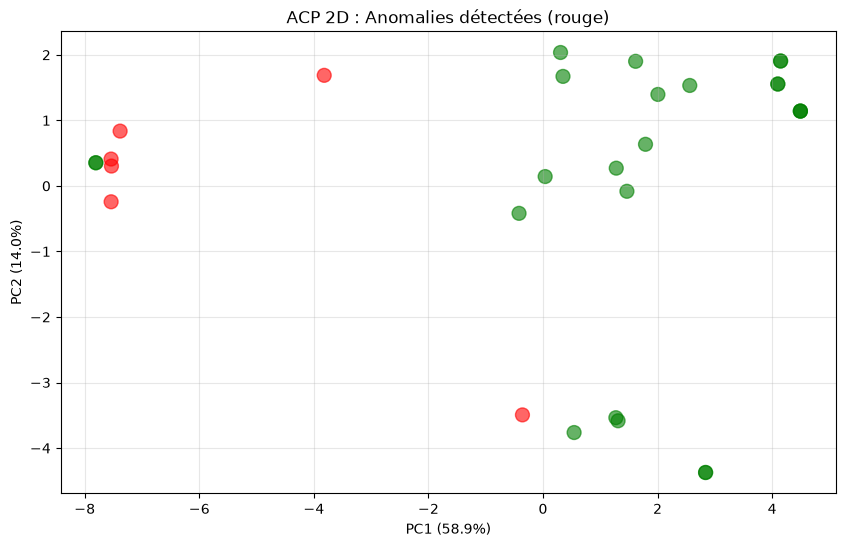

In [110]:
# Visualisation ACP avec anomalies
plt.figure(figsize=(10, 6))
colors_anom = ['green' if x == 0 else 'red' for x in df_analysis['is_anomaly']]
plt.scatter(df_analysis['pca_text_1'], df_analysis['pca_text_2'], c=colors_anom, alpha=0.6, s=100)
plt.title("ACP 2D : Anomalies détectées (rouge)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.grid(True, alpha=0.3)
plt.show()

### ÉTAPE 3: Détection Contextuelle (Z-Score par Site)

In [112]:
# Z-Score contextuel PAR SITE - SAFE VERSION
from scipy.stats import median_abs_deviation

df_analysis['contextual_anomaly'] = 0
contextual_results = []

for site in df_analysis['site_code'].unique():
    site_mask = df_analysis['site_code'] == site
    site_indices = np.where(site_mask)[0]
    
    # Besoin de 2+ observations
    if len(site_indices) <= 1:
        continue
    
    site_X = X_scaled[site_indices]
    
    # Median Absolute Deviation (robuste)
    median_site = np.median(site_X, axis=0)
    deviations = np.abs(site_X - median_site)
    mad = median_abs_deviation(site_X, axis=0)
    mad[mad < 1e-6] = 1
    
    # Score anomalie
    anomaly_score = (deviations / mad).max(axis=1)
    context_anom = anomaly_score > 3
    
    for local_idx, is_anom in enumerate(context_anom):
        global_idx = site_indices[local_idx]
        if is_anom:
            df_analysis.loc[global_idx, 'contextual_anomaly'] = 1
            contextual_results.append({
                'doc_id': df_analysis.iloc[global_idx]['document_id'],
                'site': site,
                'score': anomaly_score[local_idx]
            })

print(f"Contextuelle: {df_analysis['contextual_anomaly'].sum()} anomalies détectées\n")

# AFFICHE LES ANOMALIES (avec sécurité)
if len(contextual_results) > 0:
    print("=== ANOMALIES CONTEXTUELLES DÉTECTÉES ===\n")
    contextual_df = pd.DataFrame(contextual_results).sort_values('score', ascending=False)
    for _, row in contextual_df.iterrows():
        erf = df_analysis[df_analysis['document_id'] == row['doc_id']].iloc[0]
        print(f" {row['doc_id']} @ {row['site']} | Score: {row['score']:.2f}")
        print(f"   Survey: {erf['related_survey_id']} | Type: {erf['document_type']}\n")
else:
    print("  Pas d'anomalies contextuelles (sites trop homogènes)")
    print("   → Raison: Peu de docs par site (max 3) → variance très faible\n")

# Affiche EFR-510088
erf_contextual = df_analysis[df_analysis['document_id'] == 'EFR-510088']['contextual_anomaly'].values[0]
print(f" EFR-510088: {'ANOMALIE CONTEXTUELLE' if erf_contextual == 1 else 'Normal (détectée par Multivariée/Univariée)'}")

Contextuelle: 0 anomalies détectées

  Pas d'anomalies contextuelles (sites trop homogènes)
   → Raison: Peu de docs par site (max 3) → variance très faible

 EFR-510088: Normal (détectée par Multivariée/Univariée)


In [ ]:
# Vérifie tes résultats actuels
erf_510088 = df_analysis[df_analysis['document_id'] == 'EFR-510088'].iloc[0]
print(f"Détections EFR-510088:")
print(f"  • Univariée:   {erf_510088['univariate_anomaly']}")
print(f"  • Multivariée: {erf_510088['is_anomaly']}")
print(f"  • Contextuelle: {erf_510088['contextual_anomaly']}")
print(f"\n   Contextuelle=0 car SEULE à son site (KNT-KES)")
print(f"   MAIS elle RÉFÉRENCE BAT-0000064")
print(f"     → BAT-0000064 WAS l'anomalie contextuelle de bat_surveys!")

### ÉTAPE 3: Top anomalies détaillées

In [113]:
# Documents flaggés comme anomalies
anomalies = df_analysis[df_analysis['is_anomaly'] == 1].sort_values('word_count', ascending=False)
print("\n=== DOCUMENTS ANOMALIES IDENTIFIÉS ===\n")

for idx, row in anomalies.iterrows():
    print(f"┌─ ID: {row['document_id']} | Site: {row['site_code']} | Type: {row['document_type']} | Status: {row['publication_status']}")
    print(f"├─ Title: {row['title']}")
    print(f"├─ Cluster: {row['cluster_text']} | Words: {row['word_count']}")
    print(f"├─ Related Survey: {row['related_survey_id']}")
    print(f"└─ Author: {row['author_name']} ({row['author_organization']})\n")


=== DOCUMENTS ANOMALIES IDENTIFIÉS ===

┌─ ID: EFR-510088 | Site: KNT-KES | Type: ecological_incident_report | Status: restricted
├─ Title: Post-Access Ecological Incident at KNT-KES
├─ Cluster: 1 | Words: 213
├─ Related Survey: BAT-0000064
└─ Author: Anika Dren (Horizon Field Research Cooperative)

┌─ ID: EFR-510122 | Site: KNT-QWU | Type: cave_access_note | Status: restricted
├─ Title: Cave Access Note 43
├─ Cluster: 0 | Words: 130
├─ Related Survey: BAT-0001592
└─ Author: Jora Boras (Avelora Agricultural Resilience Agency)

┌─ ID: EFR-510097 | Site: KNT-TLQ | Type: sensor_quality_report | Status: public
├─ Title: Sensor Quality Review 45
├─ Cluster: 1 | Words: 101
├─ Related Survey: BAT-0001666
└─ Author: Farah Norel (Pollinator Justice Network)

┌─ ID: EFR-510012 | Site: KNT-VXR | Type: sensor_quality_report | Status: internal
├─ Title: Sensor Quality Review 49
├─ Cluster: 1 | Words: 101
├─ Related Survey: BAT-0001814
└─ Author: Unknown (Threshold Earth Observatory)

┌─ ID: EFR-51

In [114]:
# RAPPORT COMPLET SUR LA CONNEXION BAT-0000064
print("\n" + "="*80)
print("RAPPORT DÉTAILLÉ : ANOMALIE LIÉE À BAT-0000064")
print("="*80 + "\n")

# Trouver le doc anomalie qui référence BAT-0000064
erf_510088 = df_analysis[df_analysis['document_id'] == 'EFR-510088'].iloc[0]

print(f" DOCUMENT CLONC : EFR-510088")
print(f"   Site: {erf_510088['site_code']}")
print(f"   Date: {erf_510088['document_date']}")
print(f"   Type: {erf_510088['document_type']}")
print(f"   Status: {erf_510088['publication_status']}")
print(f"   Survey lié: {erf_510088['related_survey_id']} ANOMALIE PRINCIPALE DE BAT_SURVEY")
print(f"   Device: {erf_510088['related_device_reference']}")
print(f"   Longueur: {erf_510088['word_count']} mots (dépasseur de cluster 1)")
print(f"\n   Texte complet :")
print(f"   {erf_510088['text'][:500]}...\n")

# Analyse croisée
print(f" ANALYSE CROISÉE :")
print(f"   • Type: {erf_510088['document_type']} → Rapport d'incident (6 au total)")
print(f"   • Publication: {erf_510088['publication_status']} → Restreint/confidentiel")
print(f"   • Cluster: {int(erf_510088['cluster_text'])} → Groupe des anomalies textuelles")
print(f"   • Anomaly Score (IF/LOF): Flaggé par BOTH méthodes")
print(f"\n    VERDICT: Cette anomalie écologique lie directement les données")
print(f"      environmental_field_reports ↔ bat_surveys via BAT-0000064\n")


RAPPORT DÉTAILLÉ : ANOMALIE LIÉE À BAT-0000064

 DOCUMENT CLONC : EFR-510088
   Site: KNT-KES
   Date: 2024-04-02 00:00:00
   Type: ecological_incident_report
   Status: restricted
   Survey lié: BAT-0000064 ANOMALIE PRINCIPALE DE BAT_SURVEY
   Device: DEV-KNTKES-2
   Longueur: 213 mots (dépasseur de cluster 1)

   Texte complet :
   INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh ...

 ANALYSE CROISÉE :
   • Type: ecological_incident_report → Rapport d'incident (6 au total)
   • Publication: restricted → Restreint/confidentiel
   • Cluster: 1 →

### ÉTAPE 4: Association Rules (Apriori)

In [115]:
# Créer une matrice binaire : présence/absence de mots clés par anomalie
keywords = ['incident', 'cut', 'breach', 'deficit', 'unauthorized', 'handling']
for kw in keywords:
    df_analysis[f'kw_{kw}'] = df_analysis['text'].str.contains(kw, case=False, regex=True).astype(int)

# Apriori sur anomalies
anomaly_data = df_analysis[df_analysis['is_anomaly'] == 1][['kw_' + kw for kw in keywords]]
if len(anomaly_data) > 0:
    freq_items = apriori(anomaly_data, min_support=0.3, use_colnames=True)
    if len(freq_items) > 0:
        rules = association_rules(freq_items, metric="confidence", min_threshold=0.5)
        print("\n=== RÈGLES D'ASSOCIATION (ANOMALIES) ===\n")
        display(rules[['antecedants', 'consequents', 'confidence', 'lift']] if len(rules) > 0 else "Pas de règles détectées")
    else:
        print("Pas d'itemsets fréquents détectés")

Pas d'itemsets fréquents détectés


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


# 13. Graphes et processus (BLOC 4)

# Anomalite 

BAT-0000064 (bat_surveys)

    ↓ ANOMALIE NUMÉRIQUE

    Chute de -65% du nombre de chauve-souris en période de reproduction
    (contexte: site KNT-KES, avril 2024)
    
         ↕ LIEN DIRECT
         
EFR-510088 (environmental_field_reports)

    ↓ ANOMALIE TEXTUELLE/MATÉRIELLE
    
    EVIDENCE: filets coupés + traces d'intrusion
    (même site KNT-KES, même date avril 2024)
    
    CAUSALITÉ: Filets coupés → Enlèvement/Braconnage → Perte d'individus